In [14]:
# Implement Micrograd 


# 1. Intuitive understanding of a derivative 
import math 
import numpy as np 
import matplotlib.pyplot as plt 
%matplotlib inline 

In [33]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data 
        self.grad = 0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op 
        self.label = label

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self,other), '+')

        def _backward():
            self.grad += 1.0 * out.grad 
            other.grad += 1.0 * out.grad 
        out._backward = _backward
        return out
 
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self,other), '*')

        def _backward():
            self.grad = other.data * out.grad 
            other.grad = self.data * out.grad   
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int,float)) # only supporting int or float
        out = Value(self.data**other, (self,), f"**{other}")

        def _backward():
            self.grad += (other * self.data**(other-1)) * out.grad 
        out._backward = _backward
        return out 
    
    def __rmul__(self, other): # other, self 
        return self * other 

    def __radd__(self, other):
        return self + other

    def __truediv__(self,other):
        return self * other**-1

    def __neg__(self):
        return self * -1 

    def __sub__(self, other):
        return self + (-other)
        

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh') 

        def _backward():
            self.grad = (1- t**2) * out.grad 
        out._backward = _backward
        return out 

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad = self.grad * out.grad
        out._backward = _backward
        return out 

    def backward(self):
        
        topo = [] # write all sequential nodes
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
    
    def __repr__(self):
        return f"Value(data={self.data})"


In [16]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')

        # if this value is a result of some operation, create an op node for it
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


In [17]:
""" Values that were floored to 0 
L.grad = 1.0   
d.grad = f.data 
f.grad = d.data 
e.grad = (d.grad * 1.0)
c.grad = (d.grad * 1.0)
a.grad = (e.grad * b.data)
b.grad = (e.grad * a.data)"""

a = Value(2.0, label='a')
b = Value(-1.0, label='b')
c = Value(2.0, label='c')
f = Value(-0.5, label='f')

e = a * b       # -2
e.label = 'e'

d = e + c       # 0
d.label = 'd'

L = d * f       # 0
L.label = 'L'
# ----------- develop TanH
e = (2*L).exp()
o = (e-1)/(e+1)
o.label = 'o'

In [18]:
# EXAMPLE 1: SIMPLE EXPRESSION
# The CRUX OF BACKPROPOGATION: LOCAL DERIVATIVE * GLOBAL DERIVATIVE (CHAIN RULE: LIEBENZ) 

# for node e, you take the dot product of derivative dL/dd (local derivative) and the derivative of dd/de (local gradient) which is 1.0
# + distributes it 
# * will swap the data 


In [19]:
o.backward()

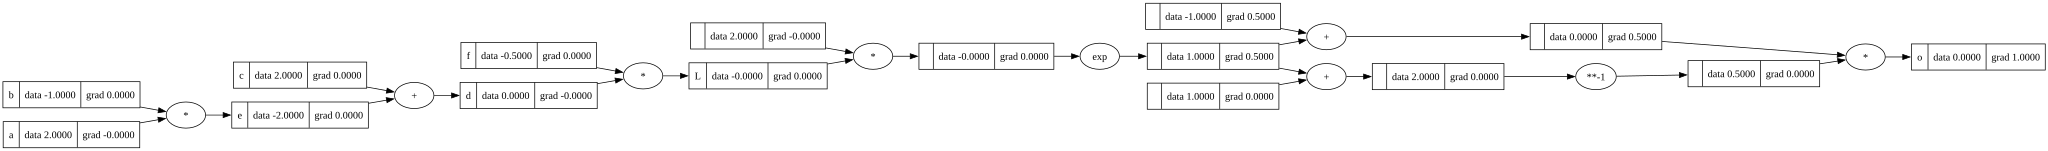

In [20]:
draw_dot(o)

In [21]:
# Example 2: Create a neuron
# In a neuron, there are usually n amounts of inputs, x1, x2, x3
# these inputs are applied a weight multiplicatively, w1,w2,w3
# these products are recursively summed x1w1 + xnwn 
# there is a bias (excitement factor) added to this sum
# and the output is sent to an activation function to create non-linearity 
# The point isnt to be in awe of the node operations, but to know that each operation has a chain rule.

# To perform a backward pass function, the initial val must be non-zero otherwise, all children nodes will be zero 

# Before backpropogation is applied on any node, it must ensured that the node after it has a gradient descent to it
# You can acheive this segmentation using something called topological sort ( all edges from nodes only go left to right)

# FIXING BUGS _-----------------------------------

# 1. When two nodes operate to create a new node (via addition), the distribtuted gradient is incorrect. 
# Simple Fix: if self.grad and other.grad are the same node, the value is being re-written instead of incremented (had a value existed previously)
# 2. Modify a value object with a non-Value object
# Simple fix: use other and make it a value object + rmul

In [25]:
# BUILDING OUT MICROGRAD USING PYTORCH (BECAUSE BOTH IN ESSENCE ARE AUTOGRADIENT ENGINES)
import torch 
import random

In [26]:


x1 = torch.Tensor([2.0]).double()     ; x1.requires_grad = True 
x2 = torch.Tensor([0.0]).double()     ; x2.requires_grad = True 
w1 = torch.Tensor([-3.0]).double()     ; w1.requires_grad = True 
w2 = torch.Tensor([1.0]).double()     ; w2.requires_grad = True 
b = torch.Tensor([6.8813735870195432]).double()     ; b.requires_grad = True 
n = x1*w1 + x2*w2 + b 
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("---")
print("x2", x2.grad.item())
print("w2", w2.grad.item())
print("x1", x1.grad.item())
print("w1", w1.grad.item())



0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [76]:
# EXAMPLE 3: BUILDING OUT NERURAL NETWORKS 
# GOAL: BUILD OUT A TWO-LAYERED MULTI-LAYER PERCEPTRON 

class Neuron: 

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # Forward pass on the Neurons 
        act = sum((wi*xi for wi,xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out  

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons] 
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x 

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]



In [208]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1]) 
n(x)

Value(data=0.8450164150699062)

In [209]:
# REAL FUNCTIONALITY IN ACTION - HAVE THE NEURAL NETWORK TAKE INPUTS, PREDICT AN OUTPUT MATHEMATICALLY, AND USE BP TO GET CLOSER TO DESIRED OUTPUT

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5], 
    [0.5, 1.0, 1.0], 
    [1.0, 1.0, -1.0],    
    ]
ys = [1.0, -1.0, -1.0, 1.0]
# HOW DO YOU TUNE THE WEIGHTS TO BETTER PREDICT THE DESIRED OUTPUT 
# SOLUTION: CREATE ONE VARIABLE THAT MEASURES THE TOTAL PERFORMENCE OF YOUR NEURAL NETWORK- CALLED THE LOSS
# IF THE PREDICTIONS ARE INCORRECT BY A MARGIN: THE LOSS IS HIGH, OTHERWISE LOW 

In [217]:

for k in range(20):

    # forward pass 
    ypred = [n(x) for x in xs] 
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backward pass + zero grad (reset all grads to 0 before updating it with the derivative)
    for p in n.parameters():
        p.grad = 0.0 
    loss.backward()

    # update 
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(f"Attempt {k}: Loss: {loss.data}")
    


# IMPLEMENT A MEAN SQUARED ERROR LOSS 
# THE LOSS WILL BE 0.0000 (the predicted - actual squared) if the prediction is close, otherwise HIGH on a moderate scale 

Attempt 0: Loss: 0.004739330457244954
Attempt 1: Loss: 0.004728131125219087
Attempt 2: Loss: 0.004679439368371938
Attempt 3: Loss: 0.004640647327833104
Attempt 4: Loss: 0.004594438429971354
Attempt 5: Loss: 0.004549567120106268
Attempt 6: Loss: 0.004505976184394354
Attempt 7: Loss: 0.004463910306935452
Attempt 8: Loss: 0.004422675499125328
Attempt 9: Loss: 0.004382576484873975
Attempt 10: Loss: 0.00434380605376858
Attempt 11: Loss: 0.0043279592435056195
Attempt 12: Loss: 0.004290251323205365
Attempt 13: Loss: 0.004259919979550657
Attempt 14: Loss: 0.004224085132318589
Attempt 15: Loss: 0.0042168530396176004
Attempt 16: Loss: 0.004209139960216788
Attempt 17: Loss: 0.004200757399807491
Attempt 18: Loss: 0.004192418892234502
Attempt 19: Loss: 0.004159903396203308


In [218]:
# IN A NUTSHELL THIS IS GRADIENT DESCENT - FORWARD PASS TO GET THE LOSS VALUE, BACKWARD PASS TO TAKE THE DERIVATIVE, THEN UPDATE TO MINIMIZE LOSS
ypred

[Value(data=0.9719120138765812),
 Value(data=-0.9955521627742376),
 Value(data=-0.9730437209339251),
 Value(data=0.9487696945679712)]